In [88]:
#Importing necessary libraries
import pandas as pd
import numpy as np
from pathlib import Path
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [89]:
# My four file names
collision_file = 'dft-road-casualty-statistics-collision-last-5-years.csv'
vehicle_file    = 'dft-road-casualty-statistics-vehicle-last-5-years.csv'
casualty_file   = 'dft-road-casualty-statistics-casualty-last-5-years.csv'
guide_file      = 'dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2024.xlsx'


In [90]:
#Reading file using pandas and printing total no of rows and columns for each
coll = pd.read_csv(collision_file, low_memory=False)
veh  = pd.read_csv(vehicle_file, low_memory=False)
cas  = pd.read_csv(casualty_file, low_memory=False)

print(f"Collisions: {coll.shape[0]:,} rows")

print(f"Collisions: {coll.shape[1]:,} columns")
print(f"Vehicles:   {veh.shape[0]:,} rows")
print(f"Vehicles:   {veh.shape[1]:,} columns")
print(f"Casualties: {cas.shape[0]:,} rows")
print(f"Casualties: {cas.shape[1]:,} columns")

Collisions: 503,475 rows
Collisions: 44 columns
Vehicles:   920,692 rows
Vehicles:   32 columns
Casualties: 640,522 rows
Casualties: 23 columns


In [91]:
#Loading code list from the Excel guide file.
guide = pd.read_excel(guide_file, sheet_name='2024_code_list')

#Cleaning cols
guide.columns = [col.strip().lower().replace(' ', '_') for col in guide.columns]

In [92]:
#Building lookup dictionaries for each (table, field) pair in the guide.
lookups = {}
for (table, field), group in guide.groupby(['table', 'field_name']):
    sub = group.dropna(subset=['code/format', 'label'])
    if not sub.empty:
        code_map = dict(zip(sub['code/format'].astype(str), sub['label'].astype(str)))
        lookups[(table.strip(), field.strip())] = code_map

In [93]:
lookups

{('casualty', 'age_band_of_casualty'): {'1': '0 - 5',
  '2': '6 - 10',
  '3': '11 - 15',
  '4': '16 - 20',
  '5': '21 - 25',
  '6': '26 - 35',
  '7': '36 - 45',
  '8': '46 - 55',
  '9': '56 - 65',
  '10': '66 - 75',
  '11': 'Over 75',
  '-1': 'Data missing or out of range'},
 ('casualty', 'age_of_casualty'): {'-1': 'Data missing or out of range'},
 ('casualty', 'bus_or_coach_passenger'): {'0': 'Not a bus or coach passenger',
  '1': 'Boarding',
  '2': 'Alighting',
  '3': 'Standing passenger',
  '4': 'Seated passenger',
  '9': 'unknown (self reported)',
  '-1': 'Data missing or out of range'},
 ('casualty', 'car_passenger'): {'0': 'Not car passenger',
  '1': 'Front seat passenger',
  '2': 'Rear seat passenger',
  '9': 'unknown (self reported)',
  '-1': 'Data missing or out of range'},
 ('casualty', 'casualty_class'): {'1': 'Driver or rider',
  '2': 'Passenger',
  '3': 'Pedestrian'},
 ('casualty',
  'casualty_distance_banding'): {'1': 'Collision occurred within 5km of casualties home post

In [94]:
# Printing basic table info and column summary
def print_columns(df, table_name):
    print(f"\n{'═'*70}")
    print(f"Table: {table_name.upper()}")
    print(f"Columns: {len(df.columns)} | Rows: {len(df):,}")
    print(f"{'═'*70}")

    info = df.dtypes.to_frame('Data Type')
    info['Non-Null Count'] = df.notna().sum()
    info['Non-Null %'] = ((df.notna().sum() / len(df)) * 100).round(1).astype(str) + '%'

    print(info)
    print(f"{'═'*70}\n")

In [95]:
print_columns(coll, "Collisions")



══════════════════════════════════════════════════════════════════════
Table: COLLISIONS
Columns: 44 | Rows: 503,475
══════════════════════════════════════════════════════════════════════
                                                 Data Type  Non-Null Count  \
collision_index                                     object          503475   
collision_year                                       int64          503475   
collision_ref_no                                    object          503475   
location_easting_osgr                              float64          503410   
location_northing_osgr                             float64          503410   
longitude                                          float64          503410   
latitude                                           float64          503410   
police_force                                         int64          503475   
collision_severity                                   int64          503475   
number_of_vehicles             

In [96]:
print_columns(veh,  "Vehicles")



══════════════════════════════════════════════════════════════════════
Table: VEHICLES
Columns: 32 | Rows: 920,692
══════════════════════════════════════════════════════════════════════
                                          Data Type  Non-Null Count Non-Null %
collision_index                              object          920692     100.0%
collision_year                                int64          920692     100.0%
collision_ref_no                             object          920692     100.0%
vehicle_reference                             int64          920692     100.0%
vehicle_type                                  int64          920692     100.0%
towing_and_articulation                       int64          920692     100.0%
vehicle_manoeuvre_historic                    int64          920692     100.0%
vehicle_manoeuvre                             int64          920692     100.0%
vehicle_direction_from                        int64          920692     100.0%
vehicle_direction_to   

In [97]:
print_columns(cas,  "Casualties")


══════════════════════════════════════════════════════════════════════
Table: CASUALTIES
Columns: 23 | Rows: 640,522
══════════════════════════════════════════════════════════════════════
                                   Data Type  Non-Null Count Non-Null %
collision_index                       object          640522     100.0%
collision_year                         int64          640522     100.0%
collision_ref_no                      object          640522     100.0%
vehicle_reference                      int64          640522     100.0%
casualty_reference                     int64          640522     100.0%
casualty_class                         int64          640522     100.0%
sex_of_casualty                        int64          640522     100.0%
age_of_casualty                        int64          640522     100.0%
age_band_of_casualty                   int64          640522     100.0%
casualty_severity                      int64          640522     100.0%
pedestrian_location

In [98]:
# Mapping field codes to readable labels using the lookup dictionary
def apply_lookup(df, table_name, field_name, new_col_name=None):
    new_col_name = new_col_name or field_name.replace('_', ' ').title() + " Label"
    key = (table_name, field_name)

    if key not in lookups:
        return df

    if field_name not in df.columns:
        df[new_col_name] = "Column not present"
        return df

    df[new_col_name] = df[field_name].astype(str).map(lookups[key]).fillna("Unknown")
    return df

In [99]:
coll = apply_lookup(coll, 'collision', 'police_force', 'Police Force Name')
coll = apply_lookup(coll, 'collision', 'collision_severity', 'Severity Label')
coll = apply_lookup(coll, 'collision', 'enhanced_collision_severity', 'Enhanced Severity Label')
coll = apply_lookup(coll, 'collision', 'day_of_week', 'Day of Week Name')
coll = apply_lookup(coll, 'collision', 'light_conditions', 'Light Conditions Label')
coll = apply_lookup(coll, 'collision', 'weather_conditions', 'Weather Conditions Label')
coll = apply_lookup(coll, 'collision', 'road_surface_conditions', 'Road Surface Conditions Label')
coll = apply_lookup(coll, 'collision', 'urban_or_rural_area', 'Urban Rural Label')
coll = apply_lookup(coll, 'collision', 'local_authority_ons_district', 'Local Authority ONS Name')
coll = apply_lookup(coll, 'collision', 'first_road_class', 'First Road Class Label')
coll = apply_lookup(coll, 'collision', 'road_type', 'Road Type Label')
coll = apply_lookup(coll, 'collision', 'junction_detail', 'Junction Detail Label')
coll = apply_lookup(coll, 'collision', 'local_authority_district', 'Local authority district Label')

In [100]:
coll=apply_lookup(coll,'collision','local_authority_highway','local authority highway Label')

In [101]:
coll

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,Light Conditions Label,Weather Conditions Label,Road Surface Conditions Label,Urban Rural Label,Local Authority ONS Name,First Road Class Label,Road Type Label,Junction Detail Label,Local authority district Label,local authority highway Label
0,2021170H10421,2021,170H10421,447098.0,532997.0,-1.270905,54.689833,17,3,2,...,Darkness - no lighting,Fine no high winds,Dry,Rural,Hartlepool,Unclassified,Single carriageway,Not at junction or within 20 metres,Code deprecated,Hartlepool
1,2021170H11231,2021,170H11231,450486.0,533118.0,-1.218333,54.690592,17,3,2,...,Daylight,Fine no high winds,Dry,Urban,Hartlepool,B,Single carriageway,Crossroads,Code deprecated,Hartlepool
2,2020170M11750,2020,170M11750,449694.0,519733.0,-1.232884,54.570397,17,3,2,...,Darkness - lights lit,Fine no high winds,Dry,Urban,Middlesbrough,Unclassified,Single carriageway,Crossroads,Middlesbrough,Middlesbrough
3,2021170M31761,2021,170M31761,449744.0,514217.0,-1.233040,54.520825,17,3,1,...,Darkness - lights lit,Fine no high winds,Wet or damp,Rural,Middlesbrough,C,Single carriageway,Not at junction or within 20 metres,Code deprecated,Middlesbrough
4,2021170S10441,2021,170S10441,445971.0,520834.0,-1.290292,54.580641,17,3,3,...,Daylight,Fine no high winds,Dry,Rural,Stockton-on-Tees,A,Dual carriageway,Not at junction or within 20 metres,Code deprecated,Stockton-on-Tees
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
503470,202163D072221,2021,63D072221,317791.0,238031.0,-3.199828,52.034574,63,2,1,...,Darkness - no lighting,Fine no high winds,Dry,Rural,Powys,Unclassified,Single carriageway,Not at junction or within 20 metres,Code deprecated,Powys
503471,202263D008922,2022,63D008922,308640.0,253525.0,-3.337343,52.172396,63,3,1,...,Daylight,Fine no high winds,Dry,Rural,Powys,A,Single carriageway,T or staggered junction,Code deprecated,Powys
503472,202263D058922,2022,63D058922,311937.0,234115.0,-3.284127,51.998470,63,3,2,...,Daylight,Fine no high winds,Dry,Rural,Powys,A,Single carriageway,Crossroads,Code deprecated,Powys
503473,202363D007623,2023,63D007623,321327.0,304240.0,-3.163807,52.630192,63,2,1,...,Darkness - no lighting,Fine no high winds,Wet or damp,Rural,Powys,A,Single carriageway,Not at junction or within 20 metres,Code deprecated,Powys


In [102]:
coll = apply_lookup(coll, 'collision', 'second_road_class', 'Second Road Class Label')

# Junction control
coll = apply_lookup(coll, 'collision', 'junction_control', 'Junction Control Label')

# Pedestrian crossing
coll = apply_lookup(coll, 'collision', 'pedestrian_crossing', 'Pedestrian Crossing Label')

In [103]:
coll

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,Urban Rural Label,Local Authority ONS Name,First Road Class Label,Road Type Label,Junction Detail Label,Local authority district Label,local authority highway Label,Second Road Class Label,Junction Control Label,Pedestrian Crossing Label
0,2021170H10421,2021,170H10421,447098.0,532997.0,-1.270905,54.689833,17,3,2,...,Rural,Hartlepool,Unclassified,Single carriageway,Not at junction or within 20 metres,Code deprecated,Hartlepool,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m
1,2021170H11231,2021,170H11231,450486.0,533118.0,-1.218333,54.690592,17,3,2,...,Urban,Hartlepool,B,Single carriageway,Crossroads,Code deprecated,Hartlepool,C,Auto traffic signal,No physical crossing facility within 50m
2,2020170M11750,2020,170M11750,449694.0,519733.0,-1.232884,54.570397,17,3,2,...,Urban,Middlesbrough,Unclassified,Single carriageway,Crossroads,Middlesbrough,Middlesbrough,Unclassified,Give way or uncontrolled,No physical crossing facility within 50m
3,2021170M31761,2021,170M31761,449744.0,514217.0,-1.233040,54.520825,17,3,1,...,Rural,Middlesbrough,C,Single carriageway,Not at junction or within 20 metres,Code deprecated,Middlesbrough,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m
4,2021170S10441,2021,170S10441,445971.0,520834.0,-1.290292,54.580641,17,3,3,...,Rural,Stockton-on-Tees,A,Dual carriageway,Not at junction or within 20 metres,Code deprecated,Stockton-on-Tees,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
503470,202163D072221,2021,63D072221,317791.0,238031.0,-3.199828,52.034574,63,2,1,...,Rural,Powys,Unclassified,Single carriageway,Not at junction or within 20 metres,Code deprecated,Powys,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m
503471,202263D008922,2022,63D008922,308640.0,253525.0,-3.337343,52.172396,63,3,1,...,Rural,Powys,A,Single carriageway,T or staggered junction,Code deprecated,Powys,Unclassified,Give way or uncontrolled,No physical crossing facility within 50m
503472,202263D058922,2022,63D058922,311937.0,234115.0,-3.284127,51.998470,63,3,2,...,Rural,Powys,A,Single carriageway,Crossroads,Code deprecated,Powys,A,Give way or uncontrolled,No physical crossing facility within 50m
503473,202363D007623,2023,63D007623,321327.0,304240.0,-3.163807,52.630192,63,2,1,...,Rural,Powys,A,Single carriageway,Not at junction or within 20 metres,Code deprecated,Powys,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m


In [104]:
if 'pedestrian_crossing_human_control_historic' in coll.columns:
    coll = apply_lookup(coll, 'collision', 'pedestrian_crossing_human_control_historic',
                        'Pedestrian Crossing Human Historic Label')

In [105]:
if 'pedestrian_crossing_physical_facilities_historic' in coll.columns:
    coll = apply_lookup(coll, 'collision', 'pedestrian_crossing_physical_facilities_historic',
                        'Pedestrian Crossing Physical Historic Label')

In [106]:
coll = apply_lookup(coll, 'collision', 'carriageway_hazards', 'Carriageway Hazards Label')

In [107]:
if 'carriageway_hazards_historic' in coll.columns:
    coll = apply_lookup(coll, 'collision', 'carriageway_hazards_historic',
                        'Carriageway Hazards Historic Label')

In [108]:
coll = apply_lookup(coll, 'collision', 'special_conditions_at_site', 'Special Conditions at Site Label')

In [109]:
if 'speed_limit' in coll.columns:
    coll['Speed Band'] = pd.cut(
        coll['speed_limit'],
        bins=[-np.inf, 0, 30, 40, 50, 60, 70, np.inf],
        labels=['Missing', '≤30 mph', '40 mph', '50 mph', '60 mph', '70 mph', 'Invalid'],
        right=True
    )
    print("Added Speed Band category")

Added Speed Band category


In [110]:
coll

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,local authority highway Label,Second Road Class Label,Junction Control Label,Pedestrian Crossing Label,Pedestrian Crossing Human Historic Label,Pedestrian Crossing Physical Historic Label,Carriageway Hazards Label,Carriageway Hazards Historic Label,Special Conditions at Site Label,Speed Band
0,2021170H10421,2021,170H10421,447098.0,532997.0,-1.270905,54.689833,17,3,2,...,Hartlepool,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph
1,2021170H11231,2021,170H11231,450486.0,533118.0,-1.218333,54.690592,17,3,2,...,Hartlepool,C,Auto traffic signal,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,≤30 mph
2,2020170M11750,2020,170M11750,449694.0,519733.0,-1.232884,54.570397,17,3,2,...,Middlesbrough,Unclassified,Give way or uncontrolled,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,≤30 mph
3,2021170M31761,2021,170M31761,449744.0,514217.0,-1.233040,54.520825,17,3,1,...,Middlesbrough,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,40 mph
4,2021170S10441,2021,170S10441,445971.0,520834.0,-1.290292,54.580641,17,3,3,...,Stockton-on-Tees,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Roadworks,Unknown,Roadworks,70 mph
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
503470,202163D072221,2021,63D072221,317791.0,238031.0,-3.199828,52.034574,63,2,1,...,Powys,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph
503471,202263D008922,2022,63D008922,308640.0,253525.0,-3.337343,52.172396,63,3,1,...,Powys,Unclassified,Give way or uncontrolled,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph
503472,202263D058922,2022,63D058922,311937.0,234115.0,-3.284127,51.998470,63,3,2,...,Powys,A,Give way or uncontrolled,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph
503473,202363D007623,2023,63D007623,321327.0,304240.0,-3.163807,52.630192,63,2,1,...,Powys,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph


In [111]:
coll

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,local authority highway Label,Second Road Class Label,Junction Control Label,Pedestrian Crossing Label,Pedestrian Crossing Human Historic Label,Pedestrian Crossing Physical Historic Label,Carriageway Hazards Label,Carriageway Hazards Historic Label,Special Conditions at Site Label,Speed Band
0,2021170H10421,2021,170H10421,447098.0,532997.0,-1.270905,54.689833,17,3,2,...,Hartlepool,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph
1,2021170H11231,2021,170H11231,450486.0,533118.0,-1.218333,54.690592,17,3,2,...,Hartlepool,C,Auto traffic signal,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,≤30 mph
2,2020170M11750,2020,170M11750,449694.0,519733.0,-1.232884,54.570397,17,3,2,...,Middlesbrough,Unclassified,Give way or uncontrolled,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,≤30 mph
3,2021170M31761,2021,170M31761,449744.0,514217.0,-1.233040,54.520825,17,3,1,...,Middlesbrough,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,40 mph
4,2021170S10441,2021,170S10441,445971.0,520834.0,-1.290292,54.580641,17,3,3,...,Stockton-on-Tees,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Roadworks,Unknown,Roadworks,70 mph
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
503470,202163D072221,2021,63D072221,317791.0,238031.0,-3.199828,52.034574,63,2,1,...,Powys,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph
503471,202263D008922,2022,63D008922,308640.0,253525.0,-3.337343,52.172396,63,3,1,...,Powys,Unclassified,Give way or uncontrolled,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph
503472,202263D058922,2022,63D058922,311937.0,234115.0,-3.284127,51.998470,63,3,2,...,Powys,A,Give way or uncontrolled,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph
503473,202363D007623,2023,63D007623,321327.0,304240.0,-3.163807,52.630192,63,2,1,...,Powys,Not at junction or within 20 metres,Data missing or out of range,No physical crossing facility within 50m,None within 50 metres,No physical crossing facilities within 50 metres,Unknown,Unknown,Unknown,60 mph


In [112]:
veh = apply_lookup(veh, 'vehicle', 'vehicle_type', 'Vehicle Type Label')


In [113]:
veh = apply_lookup(veh, 'vehicle', 'sex_of_driver', 'Sex of Driver Label')


In [114]:
veh = apply_lookup(veh, 'vehicle', 'journey_purpose_of_driver', 'Journey Purpose Label')

In [115]:
veh = apply_lookup(veh, 'vehicle', 'vehicle_type', 'Vehicle Type Label')
veh = apply_lookup(veh, 'vehicle', 'towing_and_articulation', 'Towing Articulation Label')
veh = apply_lookup(veh, 'vehicle', 'vehicle_manoeuvre', 'Vehicle Manoeuvre Label')
veh = apply_lookup(veh, 'vehicle', 'vehicle_manoeuvre_historic', 'Vehicle Manoeuvre Historic Label')
veh = apply_lookup(veh, 'vehicle', 'vehicle_location_restricted_lane', 'Restricted Lane Location Label')

In [116]:
veh = apply_lookup(veh, 'vehicle', 'hit_object_in_carriageway', 'Hit Object In Carriageway Label')

In [117]:
veh = apply_lookup(veh, 'vehicle', 'hit_object_off_carriageway', 'Hit Object Off Carriageway Label')

In [118]:
veh = apply_lookup(veh, 'vehicle', 'first_point_of_impact', 'First Point of Impact Label')

In [119]:
veh = apply_lookup(veh, 'vehicle', 'journey_purpose_of_driver', 'Journey Purpose Label')

In [120]:
veh = apply_lookup(veh, 'vehicle', 'sex_of_driver', 'Sex of Driver Label')

In [121]:
veh = apply_lookup(veh, 'vehicle', 'age_band_of_driver', 'Driver Age Band Label')

In [122]:
veh = apply_lookup(veh, 'vehicle', 'propulsion_code', 'Propulsion Code Label') #fuel type

In [123]:
cas = apply_lookup(cas, 'casualty', 'casualty_type', 'Casualty Type Label')
cas = apply_lookup(cas, 'casualty', 'casualty_severity', 'Casualty Severity Label')
cas = apply_lookup(cas, 'casualty', 'sex_of_casualty', 'Sex of Casualty Label')
cas = apply_lookup(cas, 'casualty', 'casualty_class', 'Casualty Class Label')

In [124]:
cas = apply_lookup(cas, 'casualty', 'enhanced_casualty_severity', 'Enhanced Casualty Severity Label')

In [125]:
cas = apply_lookup(cas, 'casualty', 'pedestrian_location', 'Pedestrian Location Label')

# Pedestrian movement
cas = apply_lookup(cas, 'casualty', 'pedestrian_movement', 'Pedestrian Movement Label')

In [126]:
cas = apply_lookup(cas, 'casualty', 'pedestrian_movement', 'Pedestrian Movement Label')

In [127]:
cas = apply_lookup(cas, 'casualty', 'car_passenger', 'Car Passenger Label')

# Bus/coach passenger position
cas = apply_lookup(cas, 'casualty', 'bus_or_coach_passenger', 'Bus/Coach Passenger Label')

In [128]:
coll['Collision_DateTime'] = pd.to_datetime(coll['date'] + ' ' + coll['time'],
                                           format='%d/%m/%Y %H:%M', errors='coerce')
coll['Year'] = coll['Collision_DateTime'].dt.year
coll['Month_Name'] = coll['Collision_DateTime'].dt.strftime('%B')
coll['Quarter'] = 'Q' + coll['Collision_DateTime'].dt.quarter.astype(str)
coll['Hour'] = coll['Collision_DateTime'].dt.hour
coll['Day_Name'] = coll['Collision_DateTime'].dt.day_name()

In [129]:
print(coll["Collision_DateTime"])

0        2021-05-22 22:44:00
1        2021-10-20 15:50:00
2        2020-12-01 18:00:00
3        2021-12-09 16:55:00
4        2021-04-12 09:02:00
                 ...        
503470   2021-09-11 01:15:00
503471   2022-02-04 14:36:00
503472   2022-07-22 15:15:00
503473   2023-01-27 06:45:00
503474   2024-06-24 17:00:00
Name: Collision_DateTime, Length: 503475, dtype: datetime64[ns]


In [130]:
print('Q' + coll['Collision_DateTime'].dt.quarter.astype(str))

0         Q2
1         Q4
2         Q4
3         Q4
4         Q2
          ..
503470    Q3
503471    Q1
503472    Q3
503473    Q1
503474    Q2
Name: Collision_DateTime, Length: 503475, dtype: object


In [131]:
cond = [
    coll['Hour'] < 6,
    (coll['Hour'] >= 6) & (coll['Hour'] < 9),
    (coll['Hour'] >= 9) & (coll['Hour'] < 16),
    (coll['Hour'] >= 16) & (coll['Hour'] < 19),
    coll['Hour'] >= 19
]
choices = ["Night (00-05)", "Morning Rush (06-08)", "Daytime (09-15)", "Evening Rush (16-18)", "Night (19-23)"]
coll['Time_of_Day'] = np.select(cond, choices, default="Unknown")

In [132]:
coll['Season'] = coll['Collision_DateTime'].dt.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}).fillna("Unknown")

In [133]:
coll['Is_Weekend'] = np.where(coll['Day_Name'].isin(['Saturday', 'Sunday']), "Weekend", "Weekday")

In [134]:
def age_group(age):
    if pd.isna(age) or age < 0: return "Unknown"
    if age <= 15: return "Child (0-15)"
    if age <= 24: return "Young Adult (16-24)"
    if age <= 44: return "Adult (25-44)"
    if age <= 64: return "Middle Aged (45-64)"
    return "Senior (65+)"


In [135]:
veh['Driver_Age_Group'] = veh['age_of_driver'].apply(age_group)

In [136]:
cas['Casualty_Age_Group'] = cas['age_of_casualty'].apply(age_group)

**Graphs**

In [137]:
cas["Casualty Severity Label"]


,Casualty Severity Label
0,Slight
1,Serious
2,Slight
3,Slight
4,Slight
...,...
640517,Slight
640518,Serious
640519,Slight
640520,Serious


In [138]:
print(cas["Casualty Class Label"].unique)

<bound method Series.unique of 0              Pedestrian
1              Pedestrian
2              Pedestrian
3              Pedestrian
4              Pedestrian
               ...       
640517         Pedestrian
640518         Pedestrian
640519         Pedestrian
640520    Driver or rider
640521    Driver or rider
Name: Casualty Class Label, Length: 640522, dtype: object>


In [139]:
yearly_coll = (
    coll.groupby(['Year', 'Severity Label'])
        .size()
        .unstack(fill_value=0)
)

# Here we need to make sure that index is integer and hence we are converting it to int
yearly_coll.index = yearly_coll.index.astype(int)


if 'Year' not in cas.columns:
    cas = cas.merge(
        coll[['collision_index', 'Year']],
        on='collision_index',
        how='left'
    )

yearly_cas_sev = (
    cas.groupby(['Year', 'Casualty Severity Label'])
       .size()
       .unstack(fill_value=0)
)

# Here we need to make sure that index is integer and hence we are converting it to int as above
yearly_cas_sev.index = yearly_cas_sev.index.astype(int)


yearly_cas_class = (
    cas.groupby(['Year', 'Casualty Class Label'])
       .size()
       .unstack(fill_value=0)
)

yearly_cas_class.index = yearly_cas_class.index.astype(int)


In [140]:
 !pip install -U kaleido

In [141]:


# Filter valid ages (1–100)
cas_violin = cas[(cas['age_of_casualty'] > 0) & (cas['age_of_casualty'] < 101)].copy()

# Create violin plot of age distribution by casualty class
fig_human = px.violin(
    cas_violin,
    x="Casualty Class Label",
    y="age_of_casualty",
    color="Casualty Class Label",
    box=True,
    points=None,
    title="<b>Age Distribution by Casualty Class</b>",
    labels={
        'age_of_casualty': '<b>Age of Person (Years)</b>',
        'Casualty Class Label': '<b>Road User Role</b>'
    },
    template="plotly_white"
)

# Style layout
fig_human.update_layout(
    showlegend=False,
    xaxis=dict(
        title_font=dict(size=18, family='Arial', color='black'),
        tickfont=dict(size=14, family='Arial', color='black')
    ),
    yaxis=dict(
        title_font=dict(size=18, family='Arial', color='black'),
        tickfont=dict(size=14, family='Arial', color='black'),
        dtick=10
    ),
    title_font=dict(size=24, family='Arial', color='black'),
    height=700
)

# Show the plot
fig_human.show(renderer="colab")





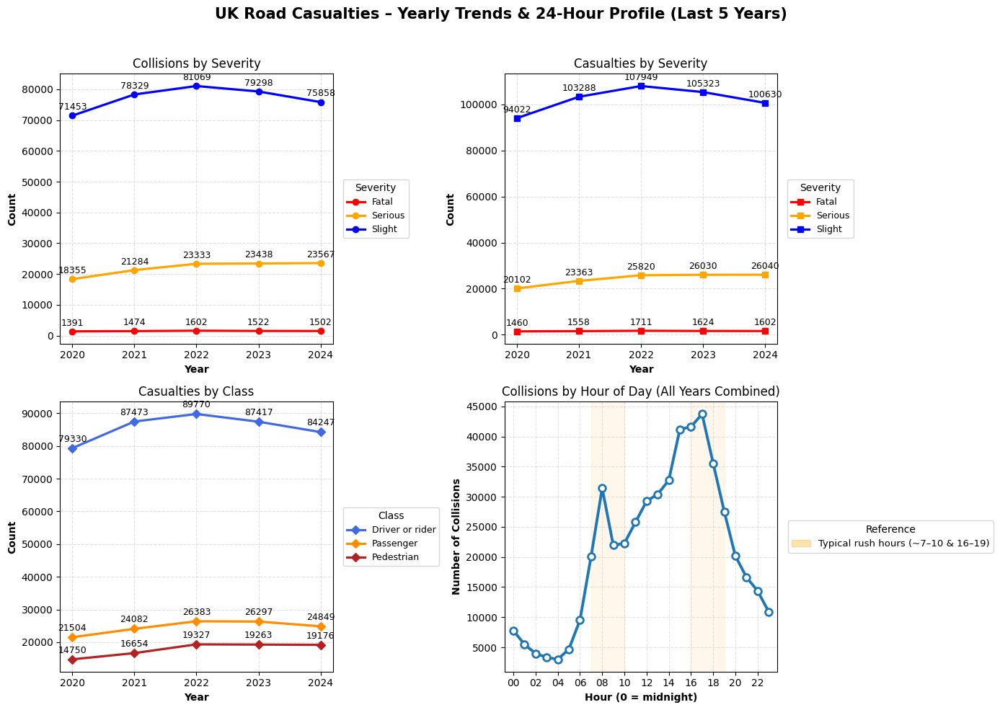

In [142]:

sev_colors = {'Fatal': 'red', 'Serious': 'orange', 'Slight': 'blue'}
class_colors = ['royalblue', 'darkorange', 'firebrick']

def label_points(ax, data, offset_factor=0.015):
    if data.empty:
        return
    max_y = data.max().max()
    offset = max_y * offset_factor
    for col in data.columns:
        for x, y in zip(data.index, data[col]):
            if y > 0:
                ax.text(x, y + offset, f'{int(y)}',
                        ha='center', va='bottom', fontsize=9,
                        color='black', fontweight='medium')

# Cleaning integer years
yearly_coll.index     = yearly_coll.index.astype(int)
yearly_cas_sev.index  = yearly_cas_sev.index.astype(int)
yearly_cas_class.index = yearly_cas_class.index.astype(int)

years = sorted(yearly_coll.index.unique().astype(int))

# Preparing hourly data
hourly_counts = coll['Hour'].value_counts().sort_index()
hourly_counts = hourly_counts.reindex(range(24), fill_value=0)

# Creating figure
fig = plt.figure(figsize=(14, 10))
fig.suptitle("UK Road Casualties – Yearly Trends & 24-Hour Profile (Last 5 Years)",
             fontsize=15, fontweight='bold', y=0.98)

ax1 = fig.add_subplot(2, 2, 1)
ax2 = fig.add_subplot(2, 2, 2)
ax3 = fig.add_subplot(2, 2, 3)
ax4 = fig.add_subplot(2, 2, 4)

# Plot 1: Collisions by Severity
for sev in yearly_coll.columns:
    ax1.plot(yearly_coll.index, yearly_coll[sev],
             marker='o', lw=2.3, label=sev,
             color=sev_colors.get(sev, 'gray'))
label_points(ax1, yearly_coll)
ax1.set_title("Collisions by Severity")
ax1.set_xlabel("Year", fontweight='bold')
ax1.set_ylabel("Count", fontweight='bold')
ax1.set_xticks(years)
ax1.set_xticklabels(years)
ax1.grid(True, ls='--', alpha=0.4)
ax1.legend(title="Severity", loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=9)

# Plot 2: Casualties by Severity
for sev in yearly_cas_sev.columns:
    ax2.plot(yearly_cas_sev.index, yearly_cas_sev[sev],
             marker='s', lw=2.3, label=sev,
             color=sev_colors.get(sev, 'gray'))
label_points(ax2, yearly_cas_sev)
ax2.set_title("Casualties by Severity")
ax2.set_xlabel("Year", fontweight='bold')
ax2.set_ylabel("Count", fontweight='bold')
ax2.set_xticks(years)
ax2.set_xticklabels(years)
ax2.grid(True, ls='--', alpha=0.4)
ax2.legend(title="Severity", loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=9)

# Plot 3: Casualties by Class
for i, cat in enumerate(yearly_cas_class.columns):
    ax3.plot(yearly_cas_class.index, yearly_cas_class[cat],
             marker='D', lw=2.3, label=cat,
             color=class_colors[i])
label_points(ax3, yearly_cas_class)
ax3.set_title("Casualties by Class")
ax3.set_xlabel("Year", fontweight='bold')
ax3.set_ylabel("Count", fontweight='bold')
ax3.set_xticks(years)
ax3.set_xticklabels(years)
ax3.grid(True, ls='--', alpha=0.4)
ax3.legend(title="Class", loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=9)

# Plot 4: 24-Hour Profile
ax4.plot(hourly_counts.index, hourly_counts.values,
         marker='o', linewidth=2.8, markersize=7,
         color='#1f77b4', markerfacecolor='white', markeredgewidth=2)

ax4.set_title("Collisions by Hour of Day (All Years Combined)")
ax4.set_xlabel("Hour (0 = midnight)", fontweight='bold')
ax4.set_ylabel("Number of Collisions", fontweight='bold')
ax4.set_xticks(range(0, 24, 2))
ax4.set_xticklabels([f"{h:02d}" for h in range(0, 24, 2)])
ax4.grid(True, ls='--', alpha=0.35)
ax4.set_xlim(-0.8, 23.8)

# Rush-hour shading
ax4.axvspan(7, 10,   alpha=0.08, color='orange')
ax4.axvspan(16, 19,  alpha=0.08, color='orange')


rush_patch = Patch(color='orange', alpha=0.3, label='Typical rush hours (~7–10 & 16–19)')
ax4.legend(
    handles=[rush_patch],
    title="Reference",
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    fontsize=9.5,
    title_fontsize=10
)


plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

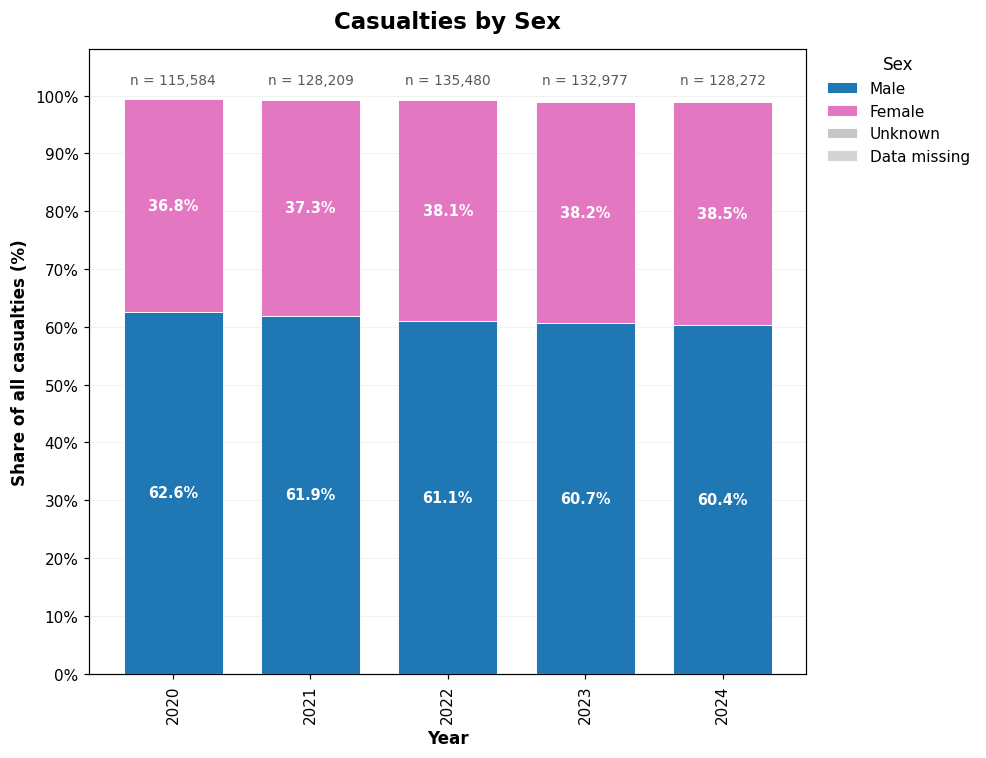

In [143]:
if 'Year' not in cas.columns:
    cas = cas.merge(
        coll[['collision_index', 'Collision_DateTime']],
        on='collision_index',
        how='left'
    )
    cas['Year'] = cas['Collision_DateTime'].dt.year.astype(int)

# We are Grouping casualties by Year and Sex
cas_year = cas.groupby(['Year', 'Sex of Casualty Label']).size().unstack(fill_value=0)
cas_year.index = cas_year.index.astype(int)

# Converting to percentages within each year
cas_pct = cas_year.div(cas_year.sum(axis=1), axis=0) * 100

# Ensuring consistent ordering of categories ─
sex_order = ['Male', 'Female', 'Unknown', 'Data missing']
cas_pct = cas_pct.reindex(columns=sex_order, fill_value=0)

colors = ['#1f77b4', '#e377c2', '#c7c7c7', '#d3d3d3']

# Stacked bar chart
fig, ax = plt.subplots(figsize=(9, 7), dpi=110)

cas_pct.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=colors[:len(cas_pct.columns)],
    width=0.72,
    edgecolor='white',
    linewidth=0.6,
    zorder=3
)

# Titles and labels stuff
ax.set_title("Casualties by Sex", fontsize=15, fontweight='bold', pad=14)
ax.set_xlabel("Year", fontsize=11, fontweight='bold')
ax.set_ylabel("Share of all casualties (%)", fontsize=11, fontweight='bold')

ax.set_ylim(0, 108)
ax.set_yticks(np.arange(0, 101, 10))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{int(y)}%"))

ax.grid(axis='y', linestyle='-', linewidth=0.6, alpha=0.18, zorder=0)

# Label larger segments only (avoid clutter) ─
for container in ax.containers:
    labels = [
        f'{bar.get_height():.1f}%' if bar.get_height() > 7 else ''
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type='center',
                 color='white', fontsize=9.5, fontweight='semibold')

# Add yearly totals above bars
for i, yr in enumerate(cas_pct.index):
    total = int(cas_year.loc[yr].sum())
    ax.text(i, 102, f"n = {total:,}", ha='center', fontsize=9, color='0.35')

# Place legend OUTSIDE (top-right, clean layout)
ax.legend(
    title="Sex",
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),   # pushes legend outside plot
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    frameon=False
)

# Adjust spacing so legend fits nicely
plt.tight_layout()
plt.subplots_adjust(right=0.82)

plt.show()


In [144]:
# Heatmap: % of Fatal collisions per Hour/Day
hm = (
    pd.crosstab(
        coll['Day_Name'], coll['Hour'],
        values=(coll['Severity Label'] == 'Fatal').astype(int),
        aggfunc='mean'
    ) * 100
).reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])

fig_hm = px.imshow(
    hm,
    labels=dict(x="Hour of Day", y="Day of Week", color="% Fatal"),
    color_continuous_scale="Reds",
    template="plotly_white"
)

fig_hm.update_layout(
    height=600,
    title=dict(
        text="<b>The Lethality Heatmap: When are Crashes Most Deadly?</b><br>"
             "<sub>Percentage of total collisions resulting in a fatality (2020–2024)</sub>",
        font_size=22,
        x=0.5,
        xanchor="center"
    ),
    yaxis_title=None,
    xaxis=dict(title="Hour of Day (24h Clock)", nticks=24)
)

fig_hm.show()

In [145]:
# Doing Filtering for London Police Forces
london_forces = ['Metropolitan Police', 'City of London']
lon_df = coll[coll['Police Force Name'].isin(london_forces)].copy()

# Performing Group by Year and Speed Limit to see the "Story of 20mph London"
lon_anim = lon_df.groupby(['Year', 'speed_limit']).agg(
    Total_Collisions=('collision_index', 'count'),
    Total_Casualties=('number_of_casualties', 'sum'),
    Fatal_Rate=('Severity Label', lambda x: (x == 'Fatal').mean() * 100)
).reset_index()

# Filtering out invalid speed limits (like -1 or 0)
lon_anim = lon_anim[lon_anim['speed_limit'] > 0]

# Creating the Animated Scatter Plot
fig_lon = px.scatter(
    lon_anim,
    x="Total_Collisions",
    y="speed_limit",
    animation_frame="Year",
    size="Total_Casualties",
    color="Fatal_Rate",
    hover_name="speed_limit",
    range_x=[0, lon_anim['Total_Collisions'].max() * 1.1],
    range_y=[10, 80],
    color_continuous_scale='Viridis',
    labels={
        'Total_Collisions': 'Number of Incidents',
        'speed_limit': 'Speed Limit (mph)',
        'Fatal_Rate': 'Fatality %'
    }
)

# Setting 3-second delay and Snap Transition
fig_lon.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 3000
fig_lon.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 0

fig_lon.update_layout(
    yaxis=dict(tickmode='linear', tick0=20, dtick=10),
    height=600,
    title=dict(
        text="<b>London: Collision Volume vs. Speed Limit (2020–2024)</b>",
        font_size=22,
        x=0.5,
        xanchor="center"
    )
)

fig_lon.show(renderer="colab")

In [146]:
main_roads = ['Single carriageway', 'Dual carriageway', 'Roundabout', 'One way street']
clean_all = coll[
    (coll['Road Type Label'].isin(main_roads)) &
    (coll['Severity Label'].notna())
].copy()

# Group by Year, Road Type, and Severity
grouped_all = clean_all.groupby(['Year', 'Road Type Label', 'Severity Label']).size().reset_index(name='Count')

# Calculating Percentage Distribution
totals_all = grouped_all.groupby(['Year', 'Road Type Label'])['Count'].transform('sum')
grouped_all['Severity_Percentage'] = (grouped_all['Count'] / totals_all * 100).round(2)

# Creating the Fast Spectrum Pulse
fig = px.scatter(
    grouped_all,
    x="Severity_Percentage",
    y="Road Type Label",
    animation_frame="Year",
    size="Count",
    size_max=80,
    color="Severity Label",
    color_discrete_map={
        'Fatal': 'rgb(255, 49, 49)',
        'Serious': 'rgb(255, 172, 28)',
        'Slight': 'rgb(57, 255, 20)'
    },
    range_x=[-5, 105],
    template="plotly_dark",
    labels={'Severity_Percentage': '% of Total Accidents', 'Road Type Label': 'Road Type'},
    category_orders={"Severity Label": ["Slight", "Serious", "Fatal"]}
)

# Setting 1-Second Timing
if fig.layout.updatemenus:
    fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 1000
    fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 500

fig.update_layout(
    showlegend=True,
    legend_title_text='Severity',
    title=dict(
        text="<b>Road Type Severity Spectrum</b>",
        font_size=22,
        x=0.5,
        xanchor="center"
    )
)

fig.show(renderer="colab")

In [147]:
# Merging Vehicle and Collision data
df_merged = pd.merge(veh, coll[['collision_index', 'Year']], on='collision_index')

# Filtering for major Age Groups and high-stakes Manoeuvres
main_ages = ['Young Adult (16-24)', 'Adult (25-44)', 'Middle Aged (45-64)', 'Senior (65+)']
mask = (
    (df_merged['Year'].between(2020, 2024)) &
    (df_merged['Driver_Age_Group'].isin(main_ages)) &
    (df_merged['Vehicle Manoeuvre Label'].str.contains('Turning right|Overtaking|Going ahead|Waiting|U-turn', case=False, na=False))
)
clean_story = df_merged[mask].copy()

# Shortening Manoeuvre Labels
def shorten_label(label):
    if 'Turning right' in label: return 'Turning Right'
    if 'Overtaking' in label: return 'Overtaking'
    if 'Going ahead' in label: return 'Going Ahead'
    if 'Waiting' in label: return 'Waiting/Held Up'
    if 'U-turn' in label: return 'U-turn'
    return label

clean_story['Manoeuvre'] = clean_story['Vehicle Manoeuvre Label'].apply(shorten_label)

# Grouping by Raw Count
grouped_story = clean_story.groupby(['Year', 'Manoeuvre', 'Driver_Age_Group']).size().reset_index(name='Accident_Count')

# Creating Plot
fig_story = px.bar(
    grouped_story,
    x="Accident_Count",
    y="Manoeuvre",
    animation_frame="Year",
    color="Driver_Age_Group",
    orientation='h',
    log_x=True,
    color_discrete_map={
        'Young Adult (16-24)': 'rgb(255, 0, 127)',
        'Adult (25-44)': 'rgb(0, 212, 255)',
        'Middle Aged (45-64)': 'rgb(57, 255, 20)',
        'Senior (65+)': 'rgb(255, 172, 28)'
    },
    template="plotly_dark",
    labels={'Accident_Count': 'Number of Vehicles Involved (Log Scale)', 'Manoeuvre': 'Vehicle Manoeuvre'},
    category_orders={
        "Driver_Age_Group": main_ages,
        "Manoeuvre": ["Going Ahead", "Waiting/Held Up", "Turning Right", "Overtaking", "U-turn"]
    }
)

# Apply 1-Second Timing
if fig_story.layout.updatemenus:
    fig_story.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 1000
    fig_story.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 500

fig_story.update_layout(
    title=dict(
        text="<b>Manoeuvre & Age Risk Profile (2020-2024)</b>",
        font_size=22,
        x=0.5,
        xanchor="center"
    )
)

fig_story.show(renderer="colab")

In [148]:
# Identify coordinate columns
lat_col = [c for c in coll.columns if 'lat' in c.lower()][0]
lon_col = [c for c in coll.columns if 'lon' in c.lower()][0]

# Cleaning Coordinates and Creating Grid
map_df = coll.dropna(subset=[lat_col, lon_col]).copy()
map_df['grid_lat'] = map_df[lat_col].round(1)
map_df['grid_lon'] = map_df[lon_col].round(1)

# Group by Grid and Year
grid_data = map_df.groupby(['Year', 'grid_lat', 'grid_lon']).size().reset_index(name='Accident_Count')

# Creating Interactive Grid Heatmap
fig_grid = px.density_mapbox(
    grid_data,
    lat='grid_lat',
    lon='grid_lon',
    z='Accident_Count',
    radius=15,
    animation_frame="Year",
    center={"lat": 54.5, "lon": -2.5},
    zoom=5,
    mapbox_style="carto-darkmatter",
    template="plotly_dark",
    labels={'grid_lat': 'Latitude', 'grid_lon': 'Longitude', 'Accident_Count': 'Accident Volume'},
    color_continuous_scale="Viridis",
    height=800
)

# 1-Second Pulse Timing
if fig_grid.layout.updatemenus:
    fig_grid.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 1000
    fig_grid.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 500

fig_grid.update_layout(
    title=dict(
        text="<b>National Pulse: Geographic Collision Density </b>",
        font_size=22,
        x=0.5,
        xanchor="center"
    )
)

fig_grid.show(renderer="colab")